# **Main agent**

one orchestrator plans a blog post, multiple workers write sections in parallel, and one reducer stitches them together
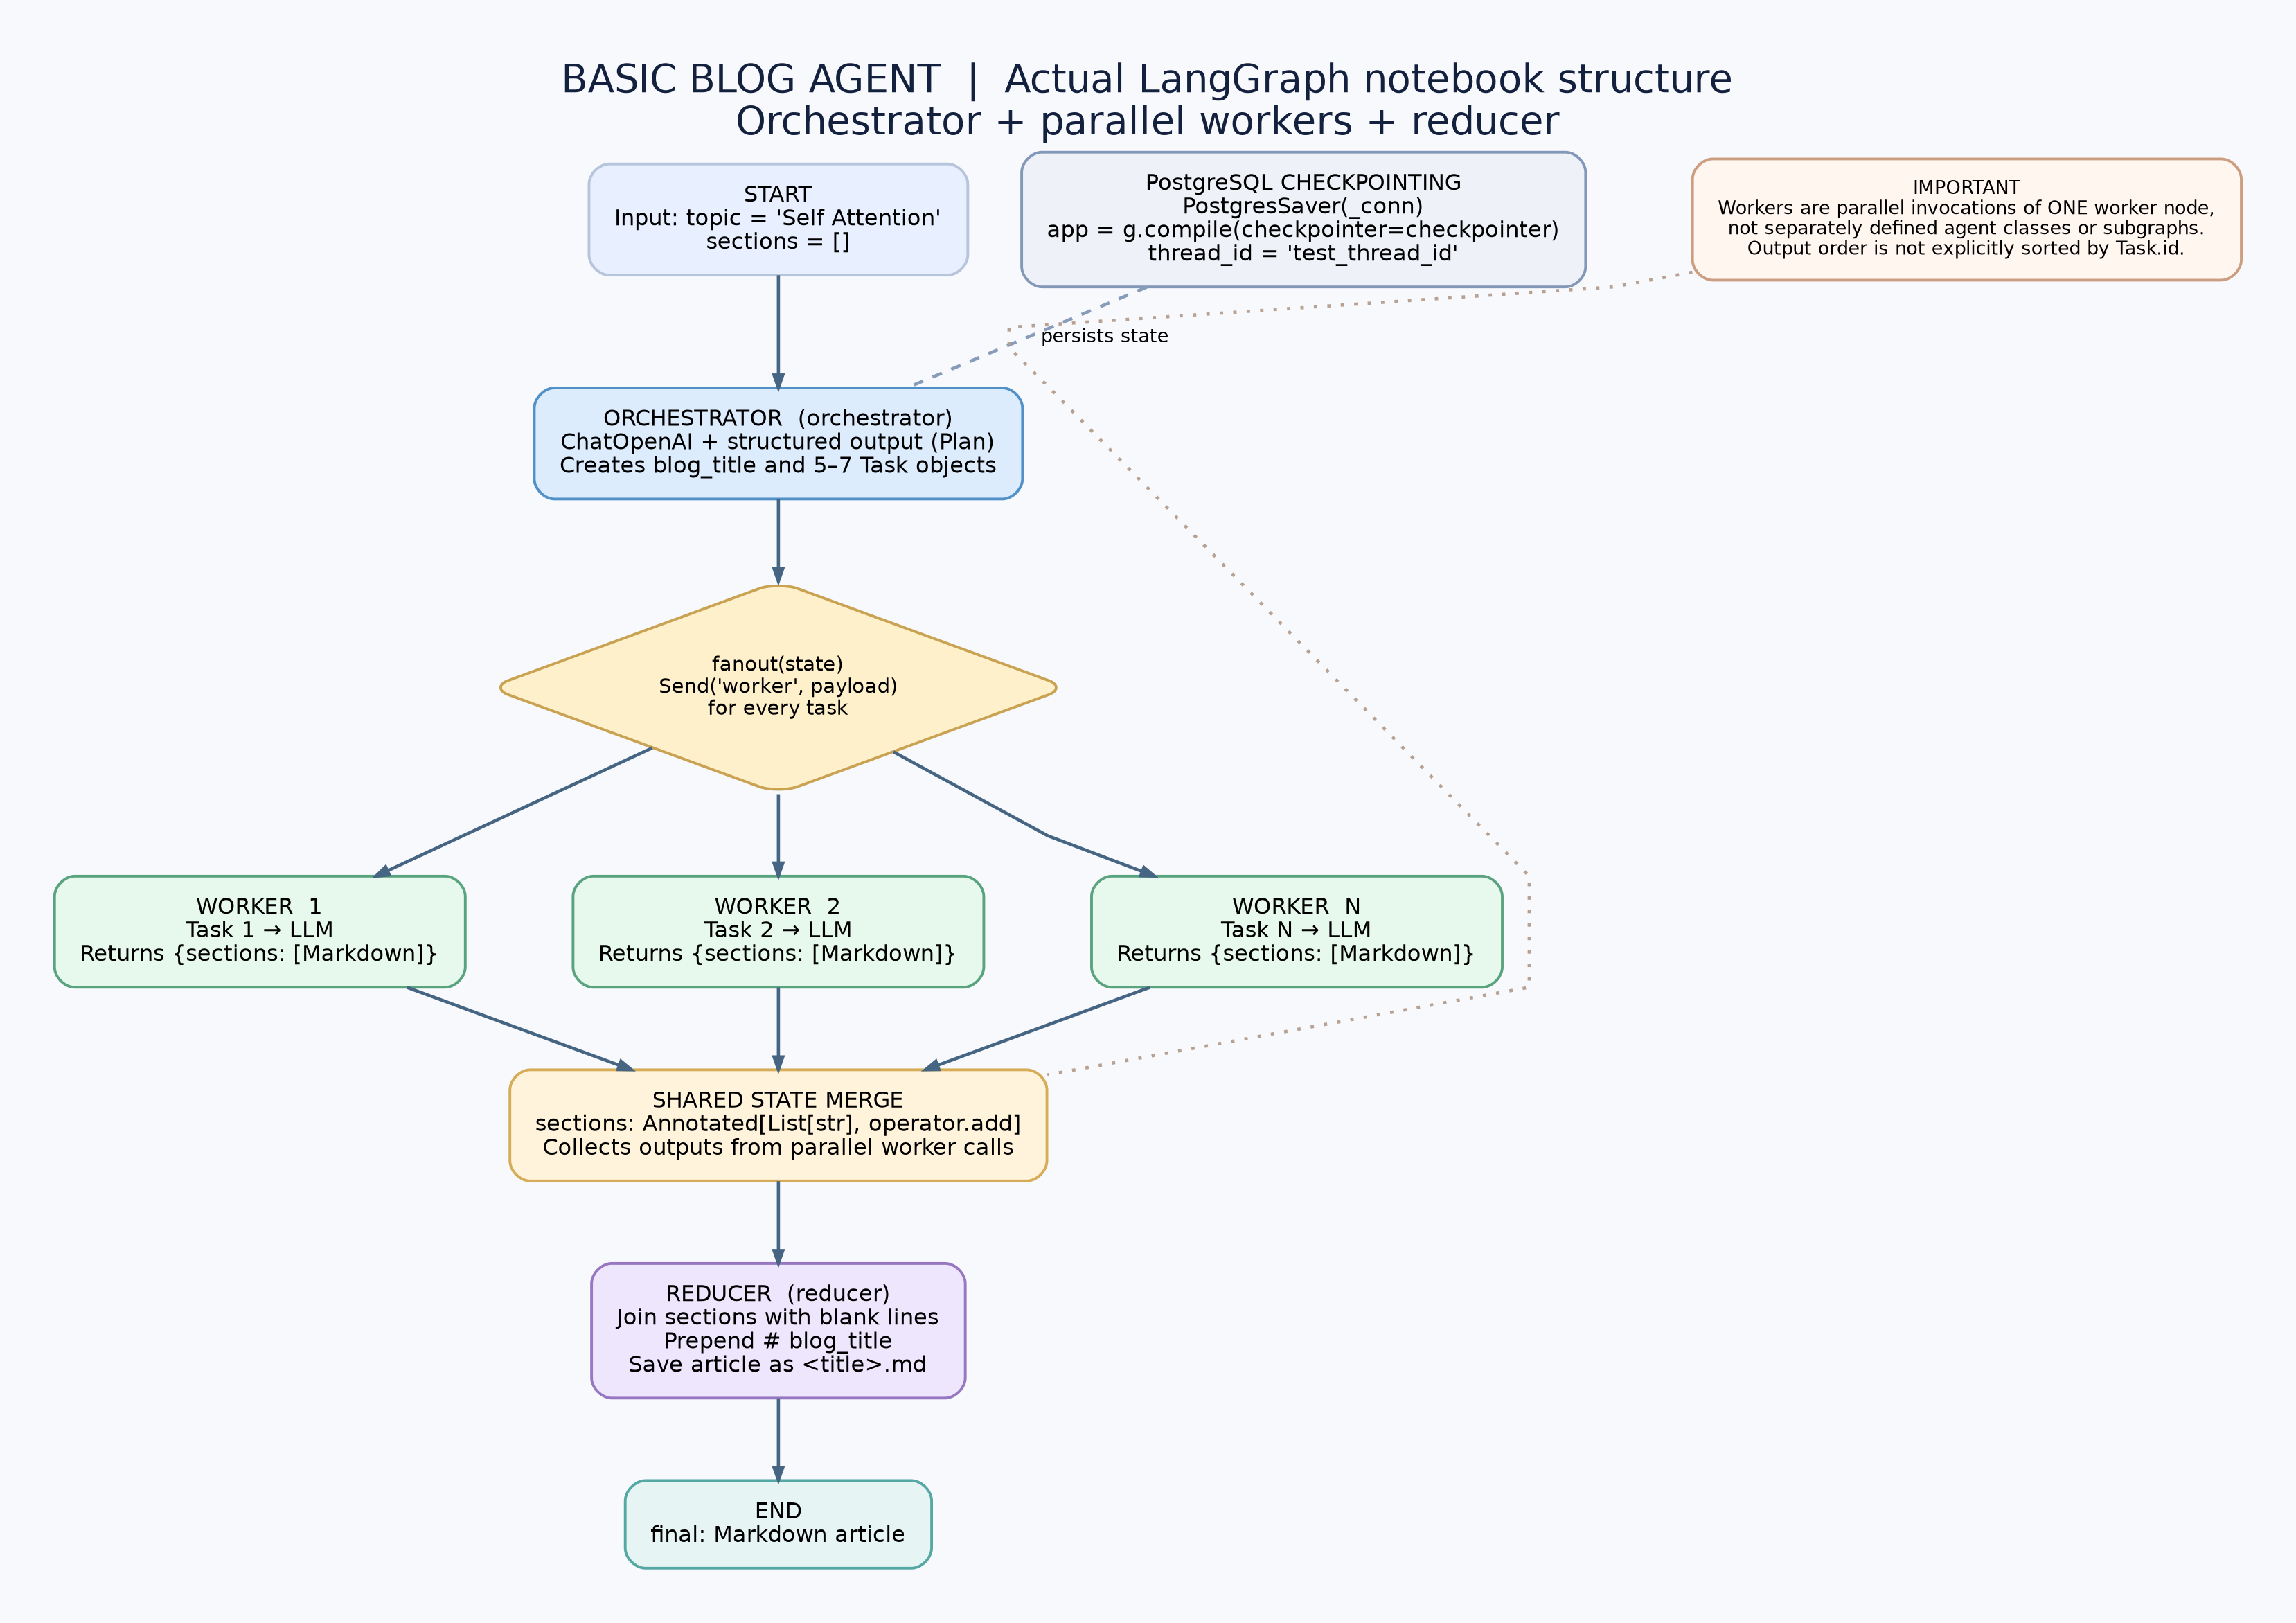

## 1. Imports and configuration

This cell loads the graph, model, and database-checkpoint dependencies. `load_dotenv()` reads local settings from `.env`; the API key and base URL configure the chat model, while `DATABASE_URL` is used later for persistent graph state. Keep secrets in environment variables rather than notebook cells.


In [11]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
import os
from langchain_openai import ChatOpenAI 
from langchain_core.messages import SystemMessage, HumanMessage

import psycopg
from psycopg.rows import dict_row
from langgraph.checkpoint.postgres import PostgresSaver
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

In [12]:
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL is missing. Please add your Render PostgreSQL External Database URL to .env"
        )

    if "sslmode=" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"

    return database_url

In [13]:
if not api_key:
    raise ValueError("OPENAI_API_KEY is missing. Please add it to your .env file.")

if not base_url:
    raise ValueError("BASE_URL is missing. Please add it to your .env file.")

## 2. Define the plan and shared state

`Task` and `Plan` are Pydantic schemas used to constrain the orchestrator's structured response. `State` is the data contract passed between graph nodes: the topic and plan are shared, each worker contributes a section, and the reducer returns the final article. `operator.add` is a list reducer, so parallel worker updates to `sections` are accumulated instead of overwriting one another.


In [14]:
class Task(BaseModel):
    
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [15]:
class Plan(BaseModel):
    
    blog_title: str
    tasks: List[Task]

In [ ]:
class State(TypedDict):
    
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

## 3. Configure the language model

The notebook creates one reusable `ChatOpenAI` client. The orchestrator uses its structured-output interface to produce a validated `Plan`; workers use the same client to write section text.


In [17]:
llm =ChatOpenAI(api_key=api_key,
            base_url=base_url,
            model="gpt-4o-mini",
            temperature=0.1,
            )

## 4. Orchestrator: make the writing plan

This node reads the topic from shared state and asks the model for a `Plan`. Returning `{'plan': plan}` updates only that state field; LangGraph carries the other state values forward.


In [18]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

## 5. Fan out (Dispatcher) section tasks in parallel

`Send` creates one worker invocation for each planned task. Each worker receives a small payload containing its task, the original topic, and the plan. This is LangGraph's map/reduce pattern: one planning step, parallel section writers, then a reducer.

```text
                    fanout
                      │
         ┌────────────┼────────────┬─────────┐
         ▼            ▼            ▼         ▼
      worker 1     worker 2     worker 3   worker 6   ← ALL IN PARALLEL
         │            │            │         │
         └────────────┴────────────┴─────────┘
                      │
                      ▼
                   reducer
```
Without Send, you'd have to loop serially: write section 1, wait, write section 2, wait… For a 6-section blog, that's 6× the wall-clock time.                   


In [19]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

## 6. Worker: write one section

A worker handles a single task, asks the model for only that section in Markdown, and returns it as a one-item `sections` update. Multiple workers can run independently; the `operator.add` reducer defined in `State` combines their outputs.


In [20]:
def worker(payload: dict) -> dict:              # payload is a plain dict from Dispatcher, not a State

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

## 7. Reducer: assemble and save the article

The reducer joins the collected sections, adds the planned title, writes a Markdown file in the notebook's current working directory, and returns the same content as `final`. This reducer is a regular graph node here; it is not a nested subgraph.


In [ ]:
from pathlib import Path

def reducer(state: State) -> dict:
    
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # ---- save to file ----
    filename = title.lower().replace(" ", "_") + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

## 8. Assemble the graph

The edges define the execution order: start with planning, dynamically fan out to workers, send their completed results to the reducer, and then finish. The conditional edge uses `fanout` to create the worker calls from the plan.


In [22]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])     #  LangGraph waits for all N workers to complete
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

## 9. Configure persistent checkpoints

The PostgreSQL checkpointer stores graph snapshots so a run can be resumed or inspected by thread. `checkpointer.setup()` creates the required checkpoint tables. This requires a reachable database and a valid `DATABASE_URL`.


In [14]:
# =========================
# PostgreSQL Checkpointer
# =========================
DATABASE_URL = get_database_url()

_conn = psycopg.connect(
    DATABASE_URL,
    autocommit=True,
    row_factory=dict_row
)

checkpointer = PostgresSaver(_conn)
checkpointer.setup()

## 10. Compile the runnable graph

Compilation turns the graph definition into an executable LangGraph application and attaches the checkpointer. The displayed object is the compiled graph, not an article run.


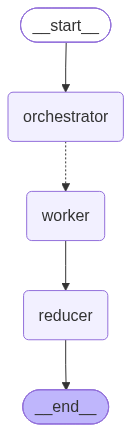

In [23]:
#app = g.compile(checkpointer=checkpointer)
app = g.compile()

app

## 11. Give the run a thread identity

The `thread_id` scopes checkpointed state for this conversation/run. Reusing a thread ID is useful for continuing the same checkpoint history; choose a new ID to start an independent run.


In [24]:
config = {
        "configurable": {
            "thread_id": "test_thread_id"
        }
    }

## 12. Invoke the workflow

`app.invoke` starts the graph with the topic and an empty initial section list. The graph then plans, writes sections in parallel, merges them, saves the Markdown file, and returns the final state.


In [25]:
out = app.invoke({"topic": "Write a blog on Quantum AI", "sections": []}, config=config)

In [26]:
out

{'topic': 'Write a blog on Quantum AI',
 'plan': Plan(blog_title='Exploring the Intersection of Quantum Computing and Artificial Intelligence', tasks=[Task(id=1, title='Introduction to Quantum AI', brief='Define Quantum AI and explain its significance in the tech landscape.'), Task(id=2, title='Understanding Quantum Computing Basics', brief='Provide a brief overview of quantum computing principles, including qubits, superposition, and entanglement.'), Task(id=3, title='The Role of AI in Quantum Computing', brief='Discuss how AI can enhance quantum computing processes, including optimization and error correction.'), Task(id=4, title='Applications of Quantum AI', brief='Explore real-world applications of Quantum AI in various fields such as healthcare, finance, and logistics.'), Task(id=5, title='Challenges and Limitations', brief='Analyze the current challenges facing Quantum AI, including technical hurdles and ethical considerations.'), Task(id=6, title='Future Prospects of Quantum AI'